# Modelling and Evaluation: Hotel Booking Cancellation Prediction

This notebook loads the cleaned dataset from `01_data_pipeline.ipynb` and follows the workflow below:

1. Load the cleaned data and list the candidate features
2. Split the cleaned data into training and test sets and set up cross-validation before the EDA and fitting in this notebook
3. Explore the training set and fix the evaluation contract (stakeholder decision, target and metrics) before modelling
4. Build the preprocessing and feature selection pipeline on the training set only. A scikit-learn `Pipeline` makes sure every step is refitted on the training part of each fold.
5. Fit the baselines and two candidate models, tune them with `GridSearchCV` and compare them with cross-validation
6. Choose the decision threshold from out-of-fold training predictions
7. Evaluate once on the held-out test set and choose the final model, then refit it on all bookings for deployment
8. Analyse the final model's errors, interpret it and check its robustness over time

In [1]:
# import libraries
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from scipy.stats import ttest_rel, wilcoxon

from sklearn import set_config
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import SelectFromModel
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    make_scorer,
    precision_score,
    recall_score,
)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_predict, cross_validate, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier

# set up display options
pd.set_option('display.max_columns', 60)
pd.set_option('display.width', 200)

# figures use Times New Roman to match the report
plt.rcParams['font.family'] = 'Times New Roman'

# set random seed for reproducibility
RANDOM_SEED = 5310
np.random.seed(RANDOM_SEED)

# set up paths
DATA_DIR = Path('data')
CLEANED_PATH = DATA_DIR / 'hotel_bookings_cleaned.csv'
OUTPUT_DIR = Path('outputs')
OUTPUT_DIR.mkdir(exist_ok=True)
# figures used in the report
FIGURE_DIR = OUTPUT_DIR / 'figures'
FIGURE_DIR.mkdir(exist_ok=True)

NOTEBOOK_START = time.time()

## 1. Cleaned Data and Feature Set

The cleaned dataset from `01_data_pipeline.ipynb` is loaded and the candidate features are listed. Nothing is fitted or explored here, so this can safely come before the split.

In [2]:
hotel_df = pd.read_csv(CLEANED_PATH)
hotel_df.shape

(87114, 30)

### 1.1 Feature Set

Features are selected for the intended decision time, subject to the availability limitation in Section 3.2. Leakage columns were already removed in `01_data_pipeline.ipynb` (2.6). The following columns are excluded here using rules that do not look at the target:

| Excluded column | Reason |
|---|---|
| `arrival_date_year` | the model is meant for future bookings, whose year never appears in training, so a year effect cannot generalise |
| `arrival_date_week_number` | carries the same seasonal information as `arrival_date_month`, as such keeping both splits one effect across two correlated features and makes logistic regression coefficients unstable. Month is kept because it is easier for the stakeholder to read. |
| `agent`, `company` | replaced by `booked_via_agent` / `booked_via_company` due to high cardinality |
| `country` | replaced by `country_group` due to high cardinality |

In [3]:
TARGET = 'is_canceled'

CATEGORICAL_FEATURES = [
    'hotel', 'arrival_date_month', 'meal', 'country_group', 'market_segment', 'distribution_channel',
    'reserved_room_type', 'deposit_type', 'customer_type',
]
NUMERIC_FEATURES = [
    'lead_time', 'arrival_date_day_of_month', 'stays_in_weekend_nights', 'stays_in_week_nights',
    'adults', 'children', 'babies', 'is_repeated_guest', 'previous_cancellations',
    'previous_bookings_not_canceled', 'adr', 'required_car_parking_spaces', 'total_of_special_requests',
    'booked_via_agent', 'booked_via_company',
]
EXCLUDED = ['arrival_date_year', 'arrival_date_week_number', 'agent', 'company', 'country']

assert set(CATEGORICAL_FEATURES + NUMERIC_FEATURES + EXCLUDED + [TARGET]) == set(hotel_df.columns), \
    'every column must be used or explicitly excluded'

X = hotel_df[CATEGORICAL_FEATURES + NUMERIC_FEATURES].copy()
y = hotel_df[TARGET].astype(int)

print(f'{len(CATEGORICAL_FEATURES)} categorical + {len(NUMERIC_FEATURES)} numeric candidate features')

9 categorical + 15 numeric candidate features


## 2. Train/Test Split and Validation Strategy

The split is defined before the EDA and fitting in this notebook. Model settings and thresholds are chosen using the training set only. Earlier cleaning decisions in `01_data_pipeline.ipynb` were informed by exploration of the full dataset, including cancellation outcomes, so the test set was not isolated from all earlier decisions. This remains a limitation of the evaluation.

* **Hold-out test set:** a random 80/20 split, **stratified** on `is_canceled` so both sets keep the same cancellation rate. The test set is used once at the end.
* **Cross-validation:** 10-fold stratified cross-validation on the training set only (k = 10 is the most common choice (Lecture 6)). The same folds are used for every model, so fold scores are paired and can be compared with a paired t-test (Lecture 6).

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_SEED,
)
cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=RANDOM_SEED)

print(f'Train: {X_train.shape}, cancellation rate {y_train.mean() * 100:.2f}%')
print(f'Test:  {X_test.shape}, cancellation rate {y_test.mean() * 100:.2f}%')

Train: (69691, 24), cancellation rate 27.72%
Test:  (17423, 24), cancellation rate 27.72%


## 3. Scope and Evaluation Contract

### 3.1 EDA on the Training Set

The EDA in this section uses the **training set only** to support the evaluation contract. Earlier full-data exploration is noted in Section 2. It checks:

* class imbalance
* timing to outcome (how far ahead bookings are made)
* cancellation policy (the penalty for cancelling a booking)

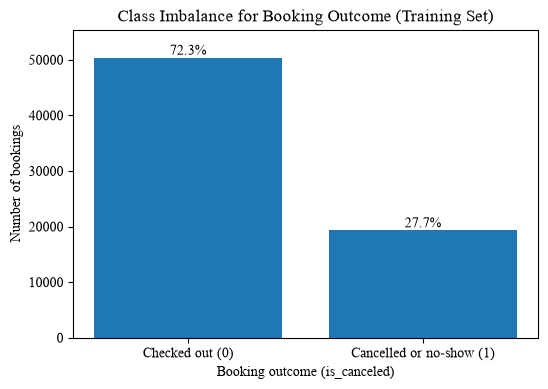

In [5]:
# training rows only, taken from the split in Section 2
train_df = hotel_df.loc[X_train.index]

# check class imbalance
target_counts = train_df['is_canceled'].value_counts()

plt.figure(figsize=(6, 4))
plt.bar(target_counts.index.astype(str), target_counts.values)
for label, count in zip(target_counts.index.astype(str), target_counts.values):
    plt.text(label, count, f'{count / len(train_df):.1%}', ha='center', va='bottom')
plt.ylim(0, target_counts.max() * 1.1)
plt.xticks(['0', '1'], ['Checked out (0)', 'Cancelled or no-show (1)'])
plt.xlabel('Booking outcome (is_canceled)')
plt.ylabel('Number of bookings')
plt.title('Class Imbalance for Booking Outcome (Training Set)')
plt.savefig(FIGURE_DIR / 'class_balance_train.png', dpi=200, bbox_inches='tight')
plt.show()

In [6]:
# lead time distribution
train_df['lead_time'].describe()

count    69691.000000
mean        83.101419
std         99.740797
min          0.000000
25%         12.000000
50%         50.000000
75%        127.000000
max       1636.000000
Name: lead_time, dtype: float64

In [7]:
median_lead = train_df['lead_time'].median()
lead_by_outcome = [train_df.loc[train_df['is_canceled'] == k, 'lead_time'] for k in (0, 1)]
print(f'median lead time: {median_lead:.0f} days overall, '
      f'{lead_by_outcome[0].median():.0f} days (checked out), {lead_by_outcome[1].median():.0f} days (cancelled or no-show)')

median lead time: 50 days overall, 38 days (checked out), 80 days (cancelled or no-show)


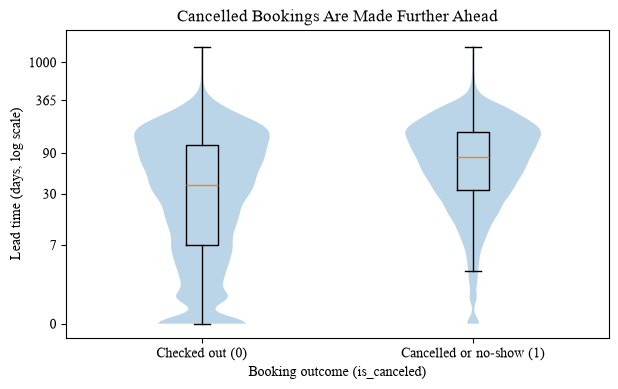

In [8]:
# violin plot of lead time by outcome
# lead time is very right-skewed, so the violins use log(1 + days) to keep every booking visible
day_ticks = [0, 7, 30, 90, 365, 1000]
plt.figure(figsize=(7, 4))
log_lead = [np.log1p(lead) for lead in lead_by_outcome]
plt.violinplot(log_lead, showextrema=False)
# boxplot inside each violin: median and middle 50% of bookings
plt.boxplot(log_lead, widths=0.12, showfliers=False)
plt.xticks([1, 2], ['Checked out (0)', 'Cancelled or no-show (1)'])
plt.yticks(np.log1p(day_ticks), day_ticks)
plt.xlabel('Booking outcome (is_canceled)')
plt.ylabel('Lead time (days, log scale)')
plt.title('Cancelled Bookings Are Made Further Ahead')
plt.show()

,bookings,cancel_rate
0-1,7203,6.1
2-7,7235,10.9
8-17,6737,21.8
18-31,6720,29.5
32-50,7191,31.1
51-74,6785,33.4
75-107,7060,34.0
108-150,6920,35.2
151-207,6886,35.4
208-1636,6954,41.2


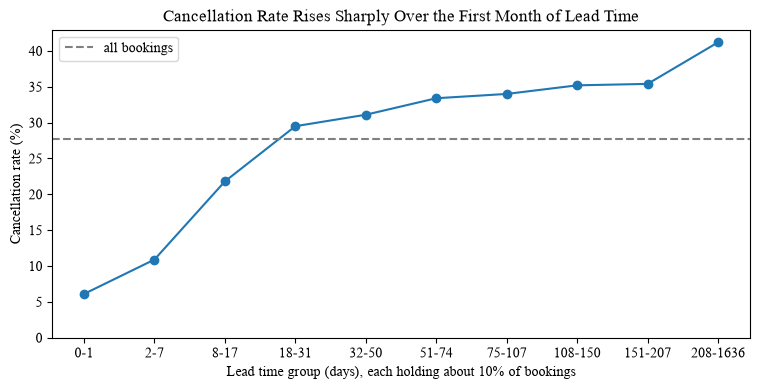

In [9]:
# cancellation rate by lead time, using 10 groups of roughly equal size (deciles)
lead_deciles = pd.qcut(train_df['lead_time'], q=10, duplicates='drop')
cancel_by_lead = train_df.groupby(lead_deciles, observed=True)['is_canceled'].agg(bookings='size', cancel_rate='mean')
cancel_by_lead['cancel_rate'] = (cancel_by_lead['cancel_rate'] * 100).round(1)

# label each group by its whole-day range, e.g. (7, 17] -> '8-17'; the first group starts at 0
decile_labels = [f'{0 if b.left < 0 else int(b.left) + 1}-{int(b.right)}' for b in cancel_by_lead.index]
display(cancel_by_lead.set_axis(decile_labels))

plt.figure(figsize=(9, 4))
plt.plot(decile_labels, cancel_by_lead['cancel_rate'], marker='o')
plt.axhline(train_df['is_canceled'].mean() * 100, color='grey', linestyle='--', label='all bookings')
plt.ylim(0, None)
plt.xlabel('Lead time group (days), each holding about 10% of bookings')
plt.ylabel('Cancellation rate (%)')
plt.title('Cancellation Rate Rises Sharply Over the First Month of Lead Time')
plt.legend()
plt.savefig(FIGURE_DIR / 'cancel_rate_by_lead_time.png', dpi=200, bbox_inches='tight')
plt.show()


In [10]:
# what cancellation policy do bookings carry, and how often does each type cancel?
deposit_summary = train_df.groupby('deposit_type')['is_canceled'].agg(bookings='size', cancel_rate='mean')
deposit_summary['share_of_bookings_%'] = (deposit_summary['bookings'] / len(train_df) * 100).round(1)
deposit_summary['cancel_rate_%'] = (deposit_summary['cancel_rate'] * 100).round(1)
deposit_summary[['bookings', 'share_of_bookings_%', 'cancel_rate_%']].sort_values('bookings', ascending=False)

,bookings,share_of_bookings_%,cancel_rate_%
deposit_type,,,
No Deposit,68587,98.4,26.7
Non Refund,1012,1.5,95.4
Refundable,92,0.1,22.8


**What this shows for the evaluation contract:**

* **Cancellations are the minority class.** 19,321 of 69,691 training bookings (27.7%) are cancelled or no-shows. A model that predicts "no cancellation" for everyone would be 72.3% accurate while catching nothing, so accuracy cannot be the primary metric. F1 for the cancellation class is used instead.
* **Bookings are made well in advance, and cancellations even more so.** The median lead time is 50 days, so there is usually time to act between confirmation and arrival. This motivates the proposed prediction horizon (from confirmation to arrival, with weekly re-scoring subject to the limitations in Section 3.2). Cancelled bookings were made further ahead (median 80 days) than bookings that arrived (median 38 days).
* **Timing matters.** The cancellation rate climbs steeply over the first month of lead time, from 6% for bookings made 0 to 1 days ahead to 29.5% at 18 to 31 days, then levels off between 31% and 41% for longer lead times. Short-notice cancellations are rarer but harder to resell, so the cost of a missed cancellation depends on when it happens.
* **Most bookings carry no cancellation penalty.** 98.4% of bookings have no deposit (26.7% cancel), while the 1.5% that are non-refundable cancel 95.4% of the time but the hotel keeps the payment. For most bookings, then, a missed cancellation is a real revenue risk. The data has no fees or deadlines beyond `deposit_type`, so the exact cost of each error cannot be measured.

### 3.2 Evaluation Contract

**Proposed stakeholder decision:** for each confirmed booking, the hotel revenue manager decides whether to place it on a weekly pre-arrival follow-up list (a reminder or a request to reconfirm), so that likely cancellations can be anticipated in room allocation.

**Prediction task:** predict whether a booking will be cancelled or end in a no-show (`is_canceled` = 1) or be checked out (`is_canceled` = 0).

* **Unit of prediction:** one booking.
* **Proposed decision time:** after booking confirmation and before arrival. Use at confirmation would require every input to be available at that time.
* **Proposed prediction horizon:** from confirmation to arrival (median lead time 50 days), with weekly re-scoring until arrival.
* **Scope:** bookings with at least one recorded adult (see `01_data_pipeline.ipynb`, 2.3).

**Data limitation:** the [original dataset description](https://pmc.ncbi.nlm.nih.gov/articles/PMC6297060/) states that, where available, field values were retrieved from change logs as of the day before arrival. These records are not necessarily confirmation-time values, and this dataset does not provide weekly snapshots. Prediction at confirmation and weekly re-scoring are therefore proposed uses, not validated capabilities. Before deployment, input availability at the intended scoring time must be checked and performance evaluated using matching snapshots.

**Consequences of errors:**

* **False negative (missed cancellation):** the hotel expects the room to be filled, but it is left empty. If the cancellation comes late there may be no time to resell the room, so revenue is lost.
* **False positive (false alarm):** a guest who plans to arrive gets an unnecessary reminder. This costs staff time and may mildly annoy the guest. If flags were used for overbooking instead, a false alarm could leave an arriving guest without a room, which is far more costly, so the model is not intended for that use.

**Primary metric: F1 score for the cancellation class.** Both false positive and false negative have a cost, so neither precision nor recall alone reflects the stakeholder's priorities. F1 is the harmonic mean of the two. The classes are imbalanced (about 72% / 28%), so accuracy is not used as the primary metric since predicting "no cancellation" for every booking already scores about 72%.

**Secondary metrics:** recall (share of cancellations caught), precision (share of flagged bookings that really cancel), and balanced accuracy (average recall across both classes). Accuracy is reported for reference only.

In [11]:
# scorers built with make_scorer with the positive class is 1 = cancelled
PRIMARY_METRIC = 'f1'
SCORING = {
    'f1': make_scorer(f1_score, pos_label=1),
    'recall': make_scorer(recall_score, pos_label=1),
    # zero_division=0: the majority-class baseline never predicts a cancellation, so its precision is 0 rather than undefined
    'precision': make_scorer(precision_score, pos_label=1, zero_division=0),
    'balanced_accuracy': make_scorer(balanced_accuracy_score),
    'accuracy': make_scorer(accuracy_score),
}

## 4. Transformations and Feature Selection Pipeline

The transformations and feature selection fitted in this section use the **training set only**. The limitation from earlier full-data exploration is noted in Section 2.

### 4.1 Leakage Check

`required_car_parking_spaces` was the numeric feature most correlated with cancellation in `01_data_pipeline.ipynb` Section 2.6. Parking requests may only be recorded when the guest arrives, which is after the decision time. If so, every booking with a parking request would be one that did not cancel, so checking the training set for that pattern is necessary to avoid leakage.

In [12]:
parking_check = pd.crosstab(X_train['required_car_parking_spaces'] > 0, y_train, margins=True)
parking_check.index = ['no parking requested', 'parking requested', 'total']
parking_check.columns = ['Check-Out (0)', 'Cancel (1)', 'total']
parking_check

,Check-Out (0),Cancel (1),total
no parking requested,44540,19321,63861
parking requested,5830,0,5830
total,50370,19321,69691


**Interpretation:** none of the 5,830 training bookings that requested a parking space was cancelled. Such a pattern is deterministic and is consistent with the field being filled in at check-in rather than at booking, which is after the decision time. It is therefore treated as leakage and removed from the feature list.

In [13]:
NUMERIC_FEATURES.remove('required_car_parking_spaces')
EXCLUDED.append('required_car_parking_spaces')
X_train = X_train.drop(columns='required_car_parking_spaces')
X_test = X_test.drop(columns='required_car_parking_spaces')
print(f'Final features: {len(CATEGORICAL_FEATURES)} categorical + {len(NUMERIC_FEATURES)} numeric')

Final features: 9 categorical + 14 numeric


### 4.2 Encoding

Models and PCA need numeric inputs on comparable scales, so the 23 features are encoded before PCA:

* **One-hot encoding** for the 9 categorical features: each category becomes its own 0/1 column. Categories such as market segment have no natural order, so numbering them 1, 2, 3 would invent one (Tutorial 10). 
* **Standardisation** for the 14 numeric features: each is rescaled to mean 0 and standard deviation 1, because logistic regression and PCA are sensitive to scale (Lecture 9). Tree models are unaffected.

The encoder is fitted on the training set only.

A common option is to merge categories with very few bookings into one "infrequent" column, because the model has too little data to learn a reliable effect for them. Whether that is needed depends on how many rare categories there are, so the training set is checked below.

In [14]:
# cut-off for grouping rare categories
MIN_FREQUENCY = cv.get_n_splits()

category_counts = pd.DataFrame([
    {'feature': col, 'category': level, 'training bookings': n}
    for col in CATEGORICAL_FEATURES
    for level, n in X_train[col].value_counts().items()
]).sort_values('training bookings')
rare = category_counts[category_counts['training bookings'] < MIN_FREQUENCY]
next_rarest = category_counts.loc[category_counts['training bookings'] >= MIN_FREQUENCY, 'training bookings'].min()

# the grouped categories plus the next rarest one, which sets the upper end of the safe range
display(category_counts[category_counts['training bookings'] <= next_rarest])
print(f'cut-off: {MIN_FREQUENCY} training bookings (one per fold)')
print(f'grouped: {len(rare)} categories, {rare["training bookings"].sum()} of {len(X_train):,} training bookings')
print(f'any cut-off from {rare["training bookings"].max() + 1} to {next_rarest} groups the same categories')

,feature,category,training bookings
33,distribution_channel,Undefined,1
42,reserved_room_type,L,4
45,deposit_type,Refundable,92


cut-off: 10 training bookings (one per fold)
grouped: 2 categories, 5 of 69,691 training bookings
any cut-off from 5 to 92 groups the same categories


**Decision: group the rare categories.** Two categories have very few training bookings: the `Undefined` distribution channel (1 booking) and room type `L` (4 bookings). They are merged into one "infrequent" column per feature for two reasons:

1. **Too little data to learn from.** With 1 or 4 bookings, the model cannot estimate a reliable effect for these categories on their own.
2. **They can be missing from a training fold.** In 10-fold cross-validation, the single `Undefined` booking falls in one fold's validation part, so that fold's training part never sees the category. With `handle_unknown='infrequent_if_exist'`, a category unseen in training is mapped to the "infrequent" column instead of causing an error.

The cut-off is set to the number of folds (`MIN_FREQUENCY` = 10), so a category keeps its own column only if it has at least one training booking per fold on average. A category with fewer bookings than folds cannot appear in every fold's validation part, so its effect cannot be checked consistently across folds.

In [15]:
# one-hot encoding for categorical features, standardisation for numeric features
encoder = ColumnTransformer([
    ('cat', OneHotEncoder(handle_unknown='infrequent_if_exist', min_frequency=MIN_FREQUENCY, sparse_output=False), CATEGORICAL_FEATURES),
    ('num', StandardScaler(), NUMERIC_FEATURES),
])
encoded_train = encoder.fit_transform(X_train)
encoded_names = encoder.get_feature_names_out()

encoded_columns = pd.Series(
    [name.split('__', 1)[1] for name in encoded_names if name.startswith('cat__')]
).map(lambda col: max((f for f in CATEGORICAL_FEATURES if col.startswith(f + '_')), key=len)).value_counts()
display(encoded_columns.rename('encoded columns').to_frame())
print(f'{len(CATEGORICAL_FEATURES)} categorical features -> {encoded_columns.sum()} columns.\n'
      f'{len(NUMERIC_FEATURES)} numeric features -> {len(NUMERIC_FEATURES)} columns.\n'
      f'{encoded_train.shape[1]} encoded columns in total')

,encoded columns
arrival_date_month,12
reserved_room_type,9
market_segment,7
meal,5
distribution_channel,5
customer_type,4
country_group,3
deposit_type,3
hotel,2


9 categorical features -> 50 columns.
14 numeric features -> 14 columns.
64 encoded columns in total


### 4.3 Modelling Pipeline

Every model uses the same four-step pipeline:

| Step | What it does | Why |
|---|---|---|
| `prep` | one-hot encodes categorical features & standardises numeric features (zero mean, unit variance) | models need numeric inputs, and logistic regression and the L1 selector are sensitive to feature scale. Standardising does not change a tree's splits |
| `select` | fits PCA and selects encoded columns within each training fold, using the rule below | uses the same selection rule for every model without fitting on validation data |
| `reduce` | `'passthrough'` by default and tuned in the grid as L1 feature selection so that the model can decide whether to further reduce the number of features | lets cross-validation decide whether reducing the selected columns further helps |
| `clf` | the classifier | the only step that differs between models |

**Column selection rule (`select` step).** PCA is used to choose which encoded columns to keep, not to replace them with component scores, so the model inputs stay readable:

1. **Variance:** keep the smallest number of principal components whose cumulative explained variance reaches **95%** (`PCA(n_components=0.95)`).
2. **Loadings:** each component is a weighted combination of all 64 encoded columns. The weights are the loadings.
3. **Column contribution:** each column's contribution is its squared loadings weighted by each component's share of the retained variance. Contributions add up to 100% across the 64 columns.
4. **Selection:** rank the columns by contribution and keep the smallest set that reaches **95% cumulative contribution**.

PCA does not use `is_canceled`. Because `select` is a pipeline step, the rule is refitted on the training part of every fold and applied to the validation part without refitting, so the chosen columns can differ slightly between folds. The columns used by the final model are shown in Section 8.1.

The pipeline is designed to prevent data leakage. `GridSearchCV` and `cross_validate` refit the whole pipeline on the training part of every fold, so the encoder's categories, the scaler's means and standard deviations, and the selected features are all learned without seeing the validation fold. The test set is only ever passed to `predict`.

In [16]:
# the same encoder as 4.2, unfitted, so every fold learns its own categories, means and standard deviations
preprocessor = clone(encoder).set_output(transform='pandas')  # keep column names so the selected columns can be picked by name

# column selection rule (see above)
PCA_VARIANCE = 0.95
CONTRIBUTION_THRESHOLD = 0.95


class KeepColumns(TransformerMixin, BaseEstimator):
    # learn the PCA-loading column selection from each fit's training data
    def __init__(self, variance=0.95, contribution=0.95, random_state=5310):
        self.variance = variance
        self.contribution = contribution
        self.random_state = random_state

    def fit(self, X, y=None):
        self.n_features_in_ = X.shape[1]
        self.feature_names_in_ = np.asarray(X.columns, dtype=object)
        self.pca_ = PCA(n_components=self.variance, random_state=self.random_state).fit(X)
        loadings = pd.DataFrame(self.pca_.components_, columns=X.columns)
        weights = self.pca_.explained_variance_ratio_
        weights = weights / weights.sum()
        self.column_contribution_ = loadings.pow(2).mul(weights, axis=0).sum(axis=0).sort_values(ascending=False)
        n_keep = min(len(self.column_contribution_),
                     int(np.searchsorted(self.column_contribution_.cumsum().values, self.contribution)) + 1)
        self.columns_ = list(self.column_contribution_.index[:n_keep])
        return self

    def transform(self, X):
        return X.loc[:, self.columns_]

    def get_feature_names_out(self, input_features=None):
        return np.asarray(self.columns_, dtype=object)


def build_pipeline(classifier):
    # clone() gives each model its own unfitted copy of the preprocessor
    return Pipeline([
        ('prep', clone(preprocessor)),
        ('select', KeepColumns(variance=PCA_VARIANCE, contribution=CONTRIBUTION_THRESHOLD, random_state=RANDOM_SEED)),
        ('reduce', 'passthrough'),
        ('clf', classifier),
    ])

# options for the 'reduce' step, tuned by cross-validation
def l1_selector(C):
    # keeps encoded columns with a non-zero L1 (lasso) coefficient
    # smaller C keeps fewer columns (Lecture 9)
    return SelectFromModel(LogisticRegression(l1_ratio=1.0, solver='liblinear', C=C, random_state=RANDOM_SEED))

def describe_reduce(step):
    if step == 'passthrough':
        return 'none'
    return f'L1 selection (C={step.estimator.C})'

set_config(display='diagram')
build_pipeline(LogisticRegression())

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('prep', ...), ('select', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('cat', ...), ('num', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the o

### 4.4 Leakage Checklist

| Check | Status |
|---|---|
| Columns that re-encode or follow the outcome (`reservation_status`, `reservation_status_date`) | removed in `01_data_pipeline.ipynb` (2.6) |
| Columns not known at the decision time (`assigned_room_type`, `booking_changes`, `days_in_waiting_list`) | removed in `01_data_pipeline.ipynb` (2.6) |
| Field likely completed at check-in (`required_car_parking_spaces`) | removed after a training-set check (4.1) |
| Duplicate rows that could appear in both train and test | removed in `01_data_pipeline.ipynb` (2.2) |
| Split made before this notebook's EDA and fitted transformations | yes, Section 2; earlier full-data exploration in 01 is a limitation |
| EDA supporting the evaluation contract uses the training set only | yes, Section 3; this does not undo earlier full-data exploration |
| PCA column selection refitted on the training part of every fold | yes, learned by `KeepColumns.fit` inside the pipeline (4.3) |
| Encoding, scaling and L1 selection refitted on the training part of every fold | yes, all inside one `Pipeline` (4.3) |
| Hyperparameters and decision threshold chosen without the test set | yes, cross-validation on training data only |
| Test set used once | yes, in the final evaluation only |

### 4.5 Experiment Log

Every cross-validation run is recorded so that each reported result can be traced back to its data, features, settings and metric, as the specification requires. Each row holds:

* a **run ID** (e.g. `B1` for a baseline, `M1-3` for the third logistic-regression setting), used to cite results in the report
* the **model**, the **features** and the **validation** scheme
* the **seed** and the **settings** (hyperparameters and `reduce` option)
* the **mean and standard deviation** of every metric across the 10 folds, so fold-to-fold variation is visible
* a **note** marking the setting selected by the grid search

The log is filled as each model is run and saved to `outputs/experiment_log.csv` at the end.

In [17]:
experiment_log = []

def log_experiment(run_id, model_name, params, cv_results, notes=''):
    # one row per cross-validation run: what was run, on what, with which settings, and how it scored
    row = {
        'run_id': run_id,
        'model': model_name,
        'features': 'PCA loadings fitted within each training fold (95% variance; 95% cumulative contribution)',
        'validation': f'{cv.get_n_splits()}-fold stratified CV on training set',
        'seed': RANDOM_SEED,
        'params': params,
        'notes': notes,
    }
    for metric in SCORING:
        scores = cv_results[f'test_{metric}']
        row[f'{metric}_mean'] = round(scores.mean(), 4)
        row[f'{metric}_sd'] = round(scores.std(), 4)
    experiment_log.append(row)
    return row


def log_grid(prefix, model_name, search):
    # log every setting a grid search tried, not only the best one
    res = search.cv_results_
    for i, params in enumerate(res['params']):
        fold_results = {
            f'test_{m}': np.array([res[f'split{k}_test_{m}'][i] for k in range(cv.get_n_splits())])
            for m in SCORING
        }
        readable = {k: (describe_reduce(v) if k == 'reduce' else v) for k, v in params.items()}
        log_experiment(f'{prefix}{i + 1}', model_name, str(readable), fold_results,
                       notes='selected' if i == search.best_index_ else '')

## 5. Baselines

* **B0, majority class:** always predicts "no cancellation".
* **B1, one rule:** a decision tree with a single split, learned from the training folds. It gives one readable rule that a manager could apply by hand, and is the real bar for the candidate models.

In [18]:
baselines = {
    'B0 majority class': build_pipeline(DummyClassifier(strategy='most_frequent')),
    'B1 one-rule (depth-1 tree)': build_pipeline(
        DecisionTreeClassifier(max_depth=1, class_weight='balanced', random_state=RANDOM_SEED)
    ),
}

cv_scores = {}
for run_id, pipe in baselines.items():
    results = cross_validate(pipe, X_train, y_train, cv=cv, scoring=SCORING, n_jobs=-1)
    cv_scores[run_id] = results
    log_experiment(run_id.split()[0], run_id, str(pipe.named_steps['clf']), results)

pd.DataFrame(experiment_log).set_index('run_id').filter(like='_mean')

,f1_mean,recall_mean,precision_mean,balanced_accuracy_mean,accuracy_mean
run_id,,,,,
B0,0.0000,0.0000,0.0000,0.500,0.7228
B1,0.4863,0.9256,0.3298,0.602,0.4578


In [19]:
# the rule B1 learns on the full training set
one_rule = baselines['B1 one-rule (depth-1 tree)'].fit(X_train, y_train)
stump = one_rule.named_steps['clf']

# check which feature the single split uses before describing it
split_column = one_rule[:-1].get_feature_names_out()[stump.tree_.feature[0]]
assert split_column == 'num__lead_time', f'B1 splits on {split_column}, not lead_time'

# lead time is standardised in the pipeline, so convert the threshold back to days
scaler = one_rule.named_steps['prep'].named_transformers_['num']
j = NUMERIC_FEATURES.index('lead_time')
cutoff_days = stump.tree_.threshold[0] * scaler.scale_[j] + scaler.mean_[j]

short_notice = X_train['lead_time'] <= cutoff_days
print(f'Rule: flag a booking as a likely cancellation if lead_time > {cutoff_days:g} days')
print(f'  lead_time <= {cutoff_days:g}: {short_notice.mean():.0%} of bookings, {y_train[short_notice].mean():.1%} cancel')
print(f'  lead_time >  {cutoff_days:g}: {(~short_notice).mean():.0%} of bookings, {y_train[~short_notice].mean():.1%} cancel')


Rule: flag a booking as a likely cancellation if lead_time > 8.5 days
  lead_time <= 8.5: 22% of bookings, 9.0% cancel
  lead_time >  8.5: 78% of bookings, 33.0% cancel


**Interpretation:**

* **B0** reaches 72.3% accuracy without identifying a single cancellation (F1 = 0), confirming that accuracy alone would be misleading here.
* **B1** learns one rule: flag a booking if its lead time is more than 8 days. The 22% of training bookings made within 8 days cancel at 9.0%, against 33.0% for the rest, which matches the lead-time pattern in the EDA (Section 3.1). The rule catches 92.6% of cancellations, but only by flagging most bookings, so just 33.0% of flagged bookings actually cancel (CV F1 0.486).

A useful candidate model must therefore beat **F1 0.486**, catching a similar share of cancellations while flagging far fewer bookings.

## 6. Candidate Models

Two models are compared:

* **Logistic regression:** simple and easy to explain. Its coefficients show the manager which booking features raise or lower the risk of cancellation, and it gives a probability for each booking. It assumes each feature has a straight-line effect on the log-odds of cancelling, so it can miss interactions, and it needs scaled inputs.
* **Random forest:** can pick up patterns a straight-line model misses, such as lead time mattering more for some market segments than others, and is a stable, strong performer (Lecture 10). It is harder to explain, since it shows which features matter but not in which direction, and it is larger and slower to run.

They are also meaningfully different as per the spec.

Both are tuned with `GridSearchCV` on the training folds only and selected by F1 (Lecture 10). Meanwhile, class weighting and the optional L1 selection step are tuned in both grids.


### 6.1 M1: Logistic Regression

The grid tunes the regularisation strength `C` (smaller means stronger regularisation), class weighting (to handle the 72/28 imbalance) and the optional L1 selection step.

In [20]:
lr_pipeline = build_pipeline(LogisticRegression(solver='liblinear', max_iter=1000, random_state=RANDOM_SEED))
lr_grid = [{
    'reduce': ['passthrough', l1_selector(0.01), l1_selector(0.001)],
    'clf__C': [0.01, 0.1, 1.0],
    'clf__class_weight': [None, 'balanced'],
}]  # 3 x 3 x 2 = 18 combinations, each fitted on 10 folds

start = time.time()
lr_search = GridSearchCV(lr_pipeline, lr_grid, cv=cv, scoring=SCORING, refit=PRIMARY_METRIC, n_jobs=-1)
lr_search.fit(X_train, y_train)
print(f'LR grid search: {time.time() - start:.0f}s')
print('Best reduce step:', describe_reduce(lr_search.best_params_['reduce']))
print('Best classifier settings:', {k: v for k, v in lr_search.best_params_.items() if k != 'reduce'})
print(f'Best CV {PRIMARY_METRIC}: {lr_search.best_score_:.4f}')

LR grid search: 33s
Best reduce step: none
Best classifier settings: {'clf__C': 1.0, 'clf__class_weight': 'balanced'}
Best CV f1: 0.5866


In [21]:
log_grid('M1-', 'Logistic regression', lr_search)
pd.DataFrame(experiment_log).query("model == 'Logistic regression'").set_index('run_id')[['params', 'f1_mean', 'f1_sd', 'recall_mean', 'precision_mean', 'notes']]

,params,f1_mean,f1_sd,recall_mean,precision_mean,notes
run_id,,,,,,
M1-1,"{'clf__C': 0.01, 'clf__class_weight': None, 'r...",0.4475,0.0123,0.3420,0.6477,
M1-2,"{'clf__C': 0.01, 'clf__class_weight': None, 'r...",0.4475,0.0121,0.3415,0.6493,
M1-3,"{'clf__C': 0.01, 'clf__class_weight': None, 'r...",0.4187,0.0153,0.3144,0.6270,
M1-4,"{'clf__C': 0.01, 'clf__class_weight': 'balance...",0.5865,0.0057,0.7308,0.4898,
M1-5,"{'clf__C': 0.01, 'clf__class_weight': 'balance...",0.5865,0.0060,0.7294,0.4905,
M1-6,"{'clf__C': 0.01, 'clf__class_weight': 'balance...",0.5769,0.0083,0.7189,0.4817,
M1-7,"{'clf__C': 0.1, 'clf__class_weight': None, 're...",0.4561,0.0130,0.3531,0.6440,
M1-8,"{'clf__C': 0.1, 'clf__class_weight': None, 're...",0.4562,0.0129,0.3530,0.6449,
M1-9,"{'clf__C': 0.1, 'clf__class_weight': None, 're...",0.4270,0.0144,0.3259,0.6195,


In [22]:
# which encoded features does the selected model use?
def kept_features(fitted_pipeline):
    all_features = fitted_pipeline.named_steps['prep'].get_feature_names_out()
    used = fitted_pipeline[:-1].get_feature_names_out()
    print(f"reduce step: {describe_reduce(fitted_pipeline.named_steps['reduce'])}; "
          f'{len(used)} model inputs from {len(all_features)} encoded features')
    dropped = sorted(set(all_features) - set(used))
    if dropped and isinstance(fitted_pipeline.named_steps['reduce'], SelectFromModel):
        print('Dropped:', ', '.join(dropped))
    return used

lr_best = lr_search.best_estimator_
lr_coefs = pd.Series(lr_best.named_steps['clf'].coef_[0], index=kept_features(lr_best))

reduce step: none; 27 model inputs from 64 encoded features


**Interpretation:**

* Class weighting makes the biggest difference. Without it, the model catches only 31% to 36% of cancellations and F1 stays between 0.42 and 0.46.
* With balanced class weights, recall rises to 72% to 73% and F1 to between 0.577 and 0.587. The cost is lower precision, which falls from between 0.62 and 0.65 to between 0.48 and 0.49.
* The regularisation strength C has almost no effect. With balanced weights and no extra feature selection, F1 is 0.587 for every value of C from 0.01 to 1.0.
* Extra L1 selection does not help. The mild setting gives the same F1 as no selection, and the strongest setting (selector C = 0.001) lowers F1 to 0.577.
* The selected model uses C = 1.0 with balanced weights and no extra feature selection. It keeps all 27 inputs and reaches a CV F1 of 0.587.

### 6.2 M2: Random Forest

The grid tunes tree depth and leaf size (both control overfitting, since fully grown trees can memorise the training data), class weighting, and the optional L1 selection step. 200 trees are used throughout.

In [23]:
rf_pipeline = build_pipeline(RandomForestClassifier(n_estimators=200, random_state=RANDOM_SEED, n_jobs=-1))
rf_grid = [{
    'reduce': ['passthrough', l1_selector(0.01)],
    'clf__max_depth': [10, None],
    'clf__min_samples_leaf': [1, 5],
    'clf__class_weight': [None, 'balanced_subsample'],
}]  # 2 x 2 x 2 x 2 = 16 combinations, each fitted on 10 folds

start = time.time()
rf_search = GridSearchCV(rf_pipeline, rf_grid, cv=cv, scoring=SCORING, refit=PRIMARY_METRIC, n_jobs=1)
rf_search.fit(X_train, y_train)
print(f'RF grid search: {time.time() - start:.0f}s')
print('Best reduce step:', describe_reduce(rf_search.best_params_['reduce']))
print('Best classifier settings:', {k: v for k, v in rf_search.best_params_.items() if k != 'reduce'})
print(f'Best CV {PRIMARY_METRIC}: {rf_search.best_score_:.4f}')
rf_kept = kept_features(rf_search.best_estimator_)

RF grid search: 298s
Best reduce step: none
Best classifier settings: {'clf__class_weight': 'balanced_subsample', 'clf__max_depth': None, 'clf__min_samples_leaf': 5}
Best CV f1: 0.6627
reduce step: none; 27 model inputs from 64 encoded features


In [24]:
log_grid('M2-', 'Random forest', rf_search)
pd.DataFrame(experiment_log).query("model == 'Random forest'").set_index('run_id')[['params', 'f1_mean', 'f1_sd', 'recall_mean', 'precision_mean', 'notes']]

,params,f1_mean,f1_sd,recall_mean,precision_mean,notes
run_id,,,,,,
M2-1,"{'clf__class_weight': None, 'clf__max_depth': ...",0.5923,0.0099,0.5115,0.7035,
M2-2,"{'clf__class_weight': None, 'clf__max_depth': ...",0.5732,0.0108,0.4799,0.7118,
M2-3,"{'clf__class_weight': None, 'clf__max_depth': ...",0.5905,0.0104,0.5096,0.7019,
M2-4,"{'clf__class_weight': None, 'clf__max_depth': ...",0.5703,0.0103,0.4758,0.7117,
M2-5,"{'clf__class_weight': None, 'clf__max_depth': ...",0.6339,0.0093,0.5765,0.7040,
M2-6,"{'clf__class_weight': None, 'clf__max_depth': ...",0.6268,0.0101,0.5684,0.6987,
M2-7,"{'clf__class_weight': None, 'clf__max_depth': ...",0.6183,0.0093,0.5435,0.7170,
M2-8,"{'clf__class_weight': None, 'clf__max_depth': ...",0.6134,0.0111,0.5350,0.7188,
M2-9,"{'clf__class_weight': 'balanced_subsample', 'c...",0.6362,0.0073,0.8047,0.5261,


**Interpretation:**

* The selected setting uses balanced subsample class weights, fully grown trees (`max_depth=None`) and at least 5 bookings per leaf. It gives the best CV F1 of 0.663, with recall 0.739, precision 0.601 and a small fold standard deviation of 0.008.
* Without class weighting, F1 is between 0.57 and 0.63. Precision is high (0.70 to 0.72) but recall is only 0.48 to 0.58.
* Depth 10 trees with class weighting push recall up to about 0.80, but precision falls to about 0.52 and F1 stays between 0.632 and 0.636.
* Fully grown trees with leaves of a single booking reach only 0.624 to 0.627. Requiring at least 5 bookings per leaf stops the deep trees from memorising the training data.
* Adding L1 selection to the selected setting gives 0.6615 against 0.6627, practically the same, so the simpler pipeline without it is kept.

## 7. Model Comparison

The baselines and both models were scored on the same 10 folds, so their fold scores can be compared pair by pair. A paired t-test checks whether one model beats another by more than the normal variation between folds (Lecture 6). The Wilcoxon signed-rank test is reported as a check that does not assume normally distributed scores.

These CV scores are slightly optimistic for M1 and M2, because their settings were chosen on the same folds. The test set provides a separate evaluation of the selected settings, subject to the earlier full-data exploration limitation in Section 2.

In [25]:
def fold_scores_at(search, index, metric):
    res = search.cv_results_
    return np.array([res[f'split{k}_test_{metric}'][index] for k in range(cv.get_n_splits())])

def best_fold_scores(search, metric):
    return fold_scores_at(search, search.best_index_, metric)

fold_scores = {
    'B0 majority class': cv_scores['B0 majority class'],
    'B1 one-rule': cv_scores['B1 one-rule (depth-1 tree)'],
    'M1 logistic regression': {f'test_{m}': best_fold_scores(lr_search, m) for m in SCORING},
    'M2 random forest': {f'test_{m}': best_fold_scores(rf_search, m) for m in SCORING},
}

cv_summary = pd.DataFrame({
    name: {m: f"{scores[f'test_{m}'].mean():.3f} ± {scores[f'test_{m}'].std():.3f}" for m in SCORING}
    for name, scores in fold_scores.items()
}).T
cv_summary

,f1,recall,precision,balanced_accuracy,accuracy
B0 majority class,0.000 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.500 ± 0.000,0.723 ± 0.000
B1 one-rule,0.486 ± 0.003,0.926 ± 0.012,0.330 ± 0.002,0.602 ± 0.004,0.458 ± 0.005
M1 logistic regression,0.587 ± 0.006,0.731 ± 0.010,0.490 ± 0.006,0.720 ± 0.005,0.715 ± 0.005
M2 random forest,0.663 ± 0.008,0.739 ± 0.013,0.601 ± 0.008,0.775 ± 0.006,0.791 ± 0.005


In [26]:
# paired tests on the primary metric across the same 10 folds
pairs = [
    ('M1 logistic regression', 'B1 one-rule'),
    ('M2 random forest', 'B1 one-rule'),
    ('M2 random forest', 'M1 logistic regression'),
]
rows = []
for a, b in pairs:
    sa = fold_scores[a][f'test_{PRIMARY_METRIC}']
    sb = fold_scores[b][f'test_{PRIMARY_METRIC}']
    rows.append({
        'comparison': f'{a} vs. {b}',
        'mean difference': round((sa - sb).mean(), 4),
        'paired t-test p': ttest_rel(sa, sb).pvalue,
        'Wilcoxon p': wilcoxon(sa, sb).pvalue,
    })
pd.DataFrame(rows).set_index('comparison')

,mean difference,paired t-test p,Wilcoxon p
comparison,,,
M1 logistic regression vs. B1 one-rule,0.1004,1.382100e-12,0.001953
M2 random forest vs. B1 one-rule,0.1765,1.995717e-14,0.001953
M2 random forest vs. M1 logistic regression,0.0761,1.008016e-11,0.001953


**Interpretation:**

* Both models clearly beat the one rule baseline. Logistic regression improves F1 by 0.1004 and the random forest by 0.1765.
* The random forest beats logistic regression by 0.0761 F1.
* All three paired t-tests give p below 0.001. The Wilcoxon p value of 0.002 is the smallest possible with 10 folds, which means the same model won in every single fold.
* These gaps are much larger than the variation between folds (standard deviations of 0.003 to 0.008), so they are not caused by a lucky split.

### 7.1 Decision Threshold

Both models output a probability, and a booking is flagged when that probability passes a threshold. The default is 0.5, but Lecture 9 notes it can be adjusted to suit the problem. The threshold is chosen from out-of-fold predictions on the training set, so the test set is still not used. The table also shows what other thresholds would mean in practice, because the hotel may want to flag fewer or more bookings than the F1 optimum.

In [27]:
thresholds = np.round(np.arange(0.20, 0.81, 0.05), 2)
threshold_tables = {}
chosen_threshold = {}

for name, search in [('M1 logistic regression', lr_search), ('M2 random forest', rf_search)]:
    # n_jobs=1 because the random forest already fits its trees in parallel
    oof_proba = cross_val_predict(search.best_estimator_, X_train, y_train, cv=cv, method='predict_proba', n_jobs=1)[:, 1]
    table = pd.DataFrame([
        {
            'threshold': t,
            'f1': f1_score(y_train, oof_proba >= t),
            'recall': recall_score(y_train, oof_proba >= t),
            'precision': precision_score(y_train, oof_proba >= t),
            'flagged_%': (oof_proba >= t).mean() * 100,
        }
        for t in thresholds
    ]).set_index('threshold').round(3)
    threshold_tables[name] = table
    chosen_threshold[name] = table[PRIMARY_METRIC].idxmax()
    print(f'{name}: best out-of-fold {PRIMARY_METRIC} at threshold {chosen_threshold[name]}')
    display(table)

M1 logistic regression: best out-of-fold f1 at threshold 0.55


,f1,recall,precision,flagged_%
threshold,,,,
0.20,0.503,0.972,0.340,79.349
0.25,0.524,0.953,0.361,73.143
0.30,0.541,0.924,0.383,66.875
0.35,0.556,0.886,0.405,60.636
0.40,0.572,0.848,0.431,54.524
0.45,0.582,0.795,0.459,48.048
0.50,0.587,0.731,0.490,41.325
0.55,0.589,0.669,0.526,35.289
0.60,0.575,0.589,0.562,29.073


M2 random forest: best out-of-fold f1 at threshold 0.5


,f1,recall,precision,flagged_%
threshold,,,,
0.20,0.568,0.970,0.401,66.994
0.25,0.586,0.955,0.423,62.535
0.30,0.605,0.933,0.448,57.708
0.35,0.625,0.899,0.479,52.083
0.40,0.643,0.852,0.517,45.707
0.45,0.658,0.800,0.559,39.636
0.50,0.663,0.739,0.601,34.136
0.55,0.659,0.680,0.640,29.460
0.60,0.647,0.622,0.674,25.576


**Interpretation:**

* F1 is almost flat between thresholds of 0.45 and 0.55 for both models, so the exact choice in that range makes little difference.
* The best threshold is 0.55 for logistic regression (F1 0.589 against 0.587 at 0.5) and 0.50 for the random forest (F1 0.663).
* The threshold mainly controls how many guests are contacted. For the random forest, a threshold of 0.40 catches 85% of cancellations but flags 46% of bookings. A threshold of 0.65 flags only 22% of bookings and 70% of them really cancel, but it catches just 57% of cancellations.
* Choosing by F1 treats a missed cancellation and a false alarm as equally costly. If the hotel can only contact a limited number of guests, or if missed cancellations cost more, the threshold should be moved accordingly.

## 8. Final Evaluation on the Test Set

Logistic regression and the random forest are refitted on all training data with their selected settings (`GridSearchCV` does this automatically), and the baselines are fitted on the same training data. Each model is then scored **once** on the test set, which was not used to choose model settings or thresholds in this notebook; the earlier exploration limitation is noted in Section 2. Logistic regression is shown at both the default 0.5 threshold and its chosen threshold of 0.55 (7.1). The random forest's chosen threshold is 0.5, so it appears once.

In [28]:
final_models = {
    'B0 majority class': baselines['B0 majority class'].fit(X_train, y_train),
    'B1 one-rule': one_rule,
    'M1 logistic regression': lr_search.best_estimator_,
    'M2 random forest': rf_search.best_estimator_,
}

def test_metrics(y_true, y_pred):
    return {
        'f1': f1_score(y_true, y_pred, zero_division=0),
        'recall': recall_score(y_true, y_pred, zero_division=0),
        'precision': precision_score(y_true, y_pred, zero_division=0),
        'balanced_accuracy': balanced_accuracy_score(y_true, y_pred),
        'accuracy': accuracy_score(y_true, y_pred),
    }

test_rows = {}
test_predictions = {}
for name, model in final_models.items():
    if name in chosen_threshold:
        proba = model.predict_proba(X_test)[:, 1]
        t = chosen_threshold[name]
        # show the default 0.5 threshold too, when the chosen threshold differs from it
        if t != 0.5:
            test_rows[f'{name} (t = 0.5)'] = test_metrics(y_test, proba >= 0.5)
        test_predictions[name] = (proba >= t).astype(int)
        test_rows[f'{name} (t = {t})'] = test_metrics(y_test, test_predictions[name])
    else:
        test_predictions[name] = model.predict(X_test)
        test_rows[name] = test_metrics(y_test, test_predictions[name])

test_results = pd.DataFrame(test_rows).T.round(3)
test_results

,f1,recall,precision,balanced_accuracy,accuracy
B0 majority class,0.000,0.000,0.000,0.500,0.723
B1 one-rule,0.490,0.932,0.332,0.606,0.461
M1 logistic regression (t = 0.5),0.598,0.741,0.501,0.729,0.724
M1 logistic regression (t = 0.55),0.598,0.678,0.535,0.726,0.747
M2 random forest (t = 0.5),0.672,0.751,0.609,0.783,0.797


**Interpretation:**

* The random forest is the best model on the test set with an F1 of 0.672, against 0.598 for logistic regression and 0.490 for the one rule baseline.
* Both test scores are close to their CV scores (0.663 and 0.587), so the models did not overfit the folds they were tuned on.
* Logistic regression gets the same F1 (0.598) at both thresholds, which confirms that the threshold choice between 0.5 and 0.55 makes little difference.
* Accuracy says little here. Logistic regression at 0.5 reaches 72.4% accuracy, barely above the 72.3% from predicting no cancellations at all, even though it catches 74% of cancellations. This is why F1 is the primary metric.

### 8.1 Final Model

The final model is chosen by **CV F1**, not by test F1. Choosing by test score would let the test set influence the choice and make the reported result optimistic. The test results above are only used to confirm the choice.

The chosen model, trained on the training set only, is evaluated once on the test set: this is its final performance. It is then refitted on **all** bookings to give the model that would be used in practice. No further score is reported for that refit, because no unseen data is left, so its expected performance is the test result.

In [29]:
candidate_searches = {'M1 logistic regression': lr_search, 'M2 random forest': rf_search}
cv_f1 = {name: round(float(search.best_score_), 4) for name, search in candidate_searches.items()}
final_name = max(cv_f1, key=cv_f1.get)
final_threshold = chosen_threshold[final_name]
final_test_f1 = {name: round(float(f1_score(y_test, test_predictions[name])), 4) for name in candidate_searches}

print('Cross-validated F1 (used to choose):', cv_f1)
print('Test F1 (check only):', final_test_f1)
print(f'\nFinal model: {final_name}, threshold {final_threshold}')
print('Test set also ranks it first:', final_name == max(final_test_f1, key=final_test_f1.get))
print('Settings:', candidate_searches[final_name].best_params_)

Cross-validated F1 (used to choose): {'M1 logistic regression': 0.5866, 'M2 random forest': 0.6627}
Test F1 (check only): {'M1 logistic regression': 0.5979, 'M2 random forest': 0.6724}

Final model: M2 random forest, threshold 0.5
Test set also ranks it first: True
Settings: {'clf__class_weight': 'balanced_subsample', 'clf__max_depth': None, 'clf__min_samples_leaf': 5, 'reduce': 'passthrough'}


,M2 random forest (t = 0.5)
f1,0.672
recall,0.751
precision,0.609
balanced_accuracy,0.783
accuracy,0.797


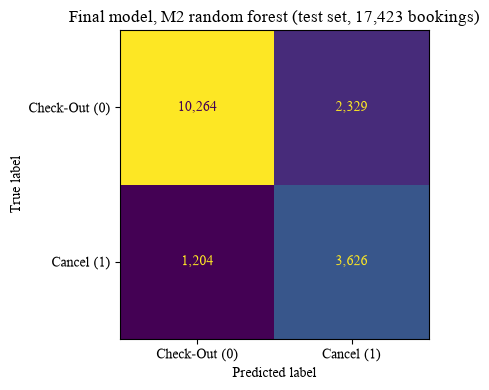

In [30]:
# final performance: the selected model (trained on the training set) on the held-out test set
final_pred = test_predictions[final_name]
final_performance = pd.Series(test_metrics(y_test, final_pred), name=f'{final_name} (t = {final_threshold})').round(3)
display(final_performance.to_frame())

fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay.from_predictions(y_test, final_pred, display_labels=['Check-Out (0)', 'Cancel (1)'],
                                        values_format=',d', ax=ax, colorbar=False)
ax.set_title(f'Final model, {final_name} (test set, {len(y_test):,} bookings)')
plt.tight_layout()
fig.savefig(FIGURE_DIR / 'final_confusion_matrix.png', dpi=200, bbox_inches='tight')

**Inputs used by the final model.** `GridSearchCV` refitted the final pipeline on the whole training set, so its `select` step learned the column selection from all 69,691 training bookings. The fold check below refits the same rule on the training part of each CV fold to show how stable the selection is.

In [31]:
final_select = candidate_searches[final_name].best_estimator_.named_steps['select']
n_encoded = final_select.n_features_in_
print(f'{final_select.pca_.n_components_} components explain {final_select.pca_.explained_variance_ratio_.sum():.1%} '
      f'of the variance in {n_encoded} encoded columns')
print(f'{len(final_select.columns_)} of {n_encoded} columns kept ({CONTRIBUTION_THRESHOLD:.0%} cumulative contribution)')

contribution = final_select.column_contribution_
selection_table = pd.DataFrame({
    'contribution_%': (contribution * 100).round(2),
    'cumulative_%': (contribution.cumsum() * 100).round(2),
}).iloc[:len(final_select.columns_)]
selection_table.index = [name.split('__', 1)[1] for name in selection_table.index]
selection_table

26 components explain 95.2% of the variance in 64 encoded columns
27 of 64 columns kept (95% cumulative contribution)


,contribution_%,cumulative_%
babies,5.83,5.83
arrival_date_day_of_month,5.83,11.66
adults,5.83,17.49
previous_bookings_not_canceled,5.83,23.32
is_repeated_guest,5.83,29.15
stays_in_weekend_nights,5.83,34.98
previous_cancellations,5.83,40.81
stays_in_week_nights,5.83,46.64
booked_via_agent,5.83,52.47
total_of_special_requests,5.83,58.30


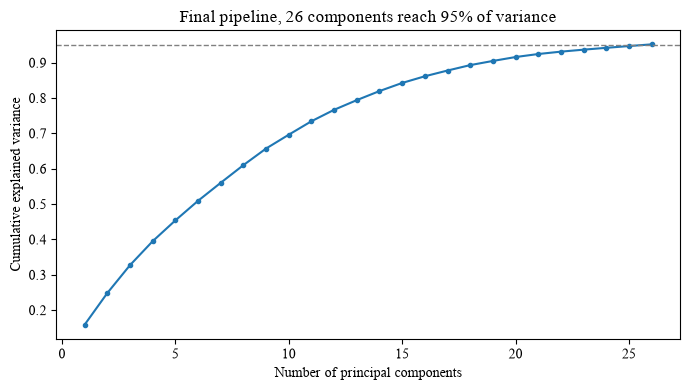

In [32]:
# cumulative variance of the components kept by the final pipeline
cumulative = np.cumsum(final_select.pca_.explained_variance_ratio_)
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(range(1, len(cumulative) + 1), cumulative, marker='.')
ax.axhline(PCA_VARIANCE, color='grey', linestyle='--', linewidth=1)
ax.set_xlabel('Number of principal components')
ax.set_ylabel('Cumulative explained variance')
ax.set_title(f'Final pipeline, {len(cumulative)} components reach {PCA_VARIANCE:.0%} of variance')
plt.tight_layout()
fig.savefig(FIGURE_DIR / 'pca_cumulative_variance.png', dpi=200, bbox_inches='tight')

In [33]:
# refit the selection rule on the training part of each CV fold
fold_selection = []
for train_idx, _ in cv.split(X_train, y_train):
    fold_X = clone(preprocessor).fit_transform(X_train.iloc[train_idx])
    fold_select = KeepColumns(variance=PCA_VARIANCE, contribution=CONTRIBUTION_THRESHOLD, random_state=RANDOM_SEED).fit(fold_X)
    fold_selection.append(set(fold_select.columns_))
fold_sizes = [len(cols) for cols in fold_selection]
same_as_final = sum(cols == set(final_select.columns_) for cols in fold_selection)
print(f'columns kept per fold: {min(fold_sizes)} to {max(fold_sizes)}')
print(f'folds with exactly the same columns as the final model: {same_as_final} of {len(fold_selection)}')
print('deposit_type columns kept by the final model:', [c for c in final_select.columns_ if 'deposit_type' in c] or 'none')

columns kept per fold: 27 to 27
folds with exactly the same columns as the final model: 10 of 10
deposit_type columns kept by the final model: none


**Interpretation:**

* The final pipeline keeps 26 principal components, which explain 95.2% of the variance, and selects 27 of the 64 encoded columns.
* The rule picks exactly the same 27 columns in all 10 CV folds, so refitting it inside each fold does not change which inputs the models see. The selection is stable.
* The ranking reflects variance, not relevance to cancellation. Each standardised numeric column has variance 1 and contributes about 5.8%, while 0/1 one hot columns have small variance and rank low.
* This is why no `deposit_type` column is kept, even though non refundable bookings cancel 95.4% of the time (Section 3.1). The selection trades some predictive information for a simpler model with 27 inputs instead of 64.

In [34]:
# final fit on all bookings, with the selected settings and threshold, for deployment
# use only the final features (X still holds required_car_parking_spaces, removed as leakage in 4.1)
X_all = hotel_df[CATEGORICAL_FEATURES + NUMERIC_FEATURES]
deployed_model = clone(candidate_searches[final_name].best_estimator_).fit(X_all, y)
print(f'{final_name} refitted on all {len(X_all):,} bookings ({y.mean():.1%} cancelled); '
      f'decision threshold {final_threshold}.')
print(f'Expected performance on new bookings: the test result above (F1 {final_performance[PRIMARY_METRIC]:.3f}).')

M2 random forest refitted on all 87,114 bookings (27.7% cancelled); decision threshold 0.5.
Expected performance on new bookings: the test result above (F1 0.672).


**Interpretation:**

* The random forest has the higher CV F1 (0.663 against 0.587), and the test set agrees, so it is the final model.
* On the 17,423 test bookings it reaches an F1 of 0.672, with recall 0.751 and precision 0.609.
* It catches 3,626 of the 4,830 cancellations and misses 1,204. It flags 5,955 bookings, of which 2,329 are false alarms, so about 61% of flagged guests really cancel.
* For use in practice, the same settings are refitted on all 87,114 bookings. Its expected performance on new bookings is this test result.

## 9. Error Analysis

Overall metrics can hide uneven performance. The final model's test set errors are broken down by booking segment, using two rates:

* **recall:** share of cancellations in the segment that the model catches
* **false alarm rate:** share of arriving guests in the segment that the model wrongly flags

Lead time is grouped by natural planning horizons (within a week, a month, a quarter, a year, and longer) so each group is easy to act on.

In [35]:
lead_time_group = pd.cut(X_test['lead_time'], bins=[-1, 7, 30, 90, 365, np.inf],
                         labels=['0 to 7', '8 to 30', '31 to 90', '91 to 365', 'over 365'])

def errors_by(group):
    df = pd.DataFrame({'group': group.values, 'y': y_test.values, 'pred': final_pred})
    return df.groupby('group', observed=True).apply(lambda g: pd.Series({
        'bookings': len(g),
        'cancel_rate': g['y'].mean(),
        'recall': g.loc[g['y'] == 1, 'pred'].mean(),
        'false_alarm_rate': g.loc[g['y'] == 0, 'pred'].mean(),
    }), include_groups=False).round(3).astype({'bookings': int})

for label, group in [('hotel', X_test['hotel']), ('market_segment', X_test['market_segment']),
                     ('deposit_type', X_test['deposit_type']), ('lead time (days)', lead_time_group)]:
    print(f'-- {label} --')
    display(errors_by(group))

-- hotel --


,bookings,cancel_rate,recall,false_alarm_rate
group,,,,
City Hotel,10567,0.306,0.751,0.218
Resort Hotel,6856,0.233,0.750,0.139


-- market_segment --


,bookings,cancel_rate,recall,false_alarm_rate
group,,,,
Aviation,42,0.143,0.500,0.000
Complementary,136,0.125,0.000,0.000
Corporate,847,0.122,0.417,0.050
Direct,2384,0.133,0.312,0.042
Groups,1076,0.292,0.920,0.109
Offline TA/TO,2766,0.160,0.858,0.097
Online TA,10171,0.357,0.775,0.290
Undefined,1,1.000,0.000,NaN


-- deposit_type --


,bookings,cancel_rate,recall,false_alarm_rate
group,,,,
No Deposit,17149,0.267,0.739,0.185
Non Refund,257,0.973,0.968,0.286
Refundable,17,0.235,1.000,0.077


-- lead time (days) --


,bookings,cancel_rate,recall,false_alarm_rate
group,,,,
0 to 7,3639,0.079,0.191,0.013
8 to 30,3221,0.252,0.630,0.172
31 to 90,4445,0.325,0.779,0.277
91 to 365,5926,0.374,0.844,0.275
over 365,192,0.349,0.940,0.152


**Interpretation:**

* **Hotel:** recall is the same for both hotels (75%), but City Hotel guests get more false alarms (21.8% against 13.9%).
* **Market segment:** cancellations are caught well in Groups (92.0%), Offline TA/TO (85.8%) and Online TA (77.5%). Online TA also gets the most false alarms, 29.0% of its arriving guests. Direct (31.2%), Corporate (41.7%) and Complementary (0%) cancellations are mostly missed. These segments cancel rarely (12% to 13%), so the model seldom flags them. Aviation (42 bookings) and Undefined (1 booking) are too small to judge.
* **Deposit type:** non refundable bookings (257 in the test set, 97.3% cancelled) are caught 96.8% of the time, even though `deposit_type` is not one of the 27 inputs. The model picks up the pattern from other inputs.
* **Lead time:** short notice cancellations (0 to 7 days) are mostly missed, with recall of only 19.1%. Bookings made 31 to 365 days ahead are caught 78% to 84% of the time, but with false alarm rates of about 28%.

The errors are uneven. Flags concentrate on Online TA and long lead bookings, while short notice cancellations and those from direct and corporate bookings mostly go unnoticed. Short notice cancellations are the hardest to resell (Section 3.1), so the hotel should not rely on the model for them. Because many flagged guests do arrive, a flag should lead to a neutral reminder, not to stricter terms for the guest.

## 10. Model Interpretation

* **Logistic regression:** the table reports coefficients and their exponentials. For standardised numeric features, `exp(coefficient)` is the odds ratio for a one-standard-deviation increase, holding other inputs fixed. For categorical features, several dummy columns can be retained, so a single exponentiated coefficient is not generally an odds ratio against all other categories. Comparing two retained categories requires `exp(coefficient_A - coefficient_B)`.
* **Random forest (final model):** impurity based feature importance (Tutorial 10). It shows how much each input is used in the trees, but not the direction of its effect.

In [36]:
odds = pd.DataFrame({'coefficient': lr_coefs, 'odds_ratio': np.exp(lr_coefs)})
odds.index = odds.index.str.split('__').str[1]
odds = odds.loc[odds['coefficient'].abs().sort_values(ascending=False).index]
print('Logistic regression: top 10 inputs by absolute coefficient')
odds.head(10).round(3)

Logistic regression: top 10 inputs by absolute coefficient


,coefficient,odds_ratio
market_segment_Offline TA/TO,-1.082,0.339
customer_type_Transient,1.014,2.756
country_group_PRT,0.911,2.486
previous_cancellations,0.741,2.098
market_segment_Online TA,0.700,2.013
hotel_Resort Hotel,-0.670,0.512
country_group_Other,-0.619,0.538
total_of_special_requests,-0.562,0.570
lead_time,0.474,1.606
market_segment_Direct,-0.434,0.648


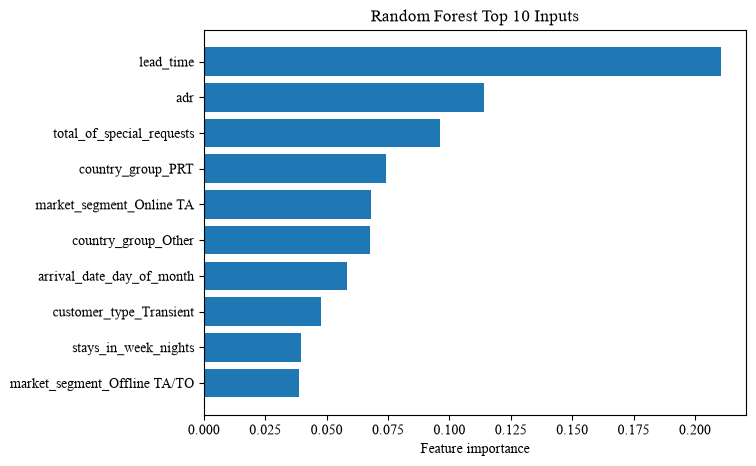

lead_time                       0.210
adr                             0.114
total_of_special_requests       0.096
country_group_PRT               0.074
market_segment_Online TA        0.068
country_group_Other             0.068
arrival_date_day_of_month       0.058
customer_type_Transient         0.048
stays_in_week_nights            0.040
market_segment_Offline TA/TO    0.039
dtype: float64

In [37]:
rf_best = rf_search.best_estimator_
rf_importance = pd.Series(rf_best.named_steps['clf'].feature_importances_,
                          index=[name.split('__', 1)[1] for name in rf_kept]).sort_values(ascending=False)

plt.figure(figsize=(7, 5))
plt.barh(rf_importance.index[:10][::-1], rf_importance.values[:10][::-1])
plt.xlabel('Feature importance')
plt.title('Random Forest Top 10 Inputs')
plt.savefig(FIGURE_DIR / 'rf_feature_importance.png', dpi=200, bbox_inches='tight')
plt.show()
rf_importance.head(10).round(3)

**Interpretation:**

* **Logistic regression:** the Transient, Portugal and Online TA indicators have positive coefficients, while Offline TA/TO, Resort Hotel, Other country group and Direct have negative coefficients. These are coefficient signs, not category-to-category odds ratios. Holding other inputs fixed, a one-standard-deviation increase in previous cancellations multiplies the odds of cancellation by 2.10, and in lead time by 1.61. The corresponding multiplier for special requests is 0.57.
* **Random forest:** importance is led by lead time (21.0%), `adr` (11.4%) and special requests (9.6%), followed by the country group (Portugal 7.4%, Other 6.8%) and Online TA (6.8%). Impurity based importance favours inputs with many distinct values, which may explain why day of month (5.8%) ranks highly.
* Both models point to the same drivers: lead time, special requests, booking through an online travel agent and the guest's country group.

These are associations, not causes. Special requests do not prevent cancellations themselves. A likely explanation is that guests who plan to stay are more likely to make them. Country group is one of the strongest drivers in both models, so the model treats guests differently by origin. This is a fairness concern that should be monitored.

## 11. Robustness Over Time

The random split mixes bookings from every period into both the training and test sets. In practice the model scores future bookings, so it matters whether cancellation behaviour changes over time. As a check, each model is retrained with its selected settings on arrivals before the latest year and tested on the latest year. Encoding, scaling and PCA column selection are refitted on the earlier bookings. Hyperparameters and thresholds still come from the original random-split training data, which includes the latest year, so this remains an exploratory sensitivity check rather than an independent future-period evaluation.

In [38]:
# arrival quarter from the year and month columns, e.g. 2016Q3
arrival_month = pd.to_datetime(hotel_df['arrival_date_month'], format='%B').dt.month
arrival_quarter = hotel_df['arrival_date_year'].astype(str) + 'Q' + ((arrival_month - 1) // 3 + 1).astype(str)
quarterly = hotel_df.groupby(arrival_quarter.rename('arrival_quarter'))[TARGET].agg(bookings='size', cancel_rate='mean')
quarterly['cancel_rate'] = (quarterly['cancel_rate'] * 100).round(1)
quarterly

,bookings,cancel_rate
arrival_quarter,,
2015Q3,6982,24.2
2015Q4,6350,17.0
2016Q1,8443,20.4
2016Q2,11073,26.2
2016Q3,12049,29.9
2016Q4,10644,28.4
2017Q1,9785,26.4
2017Q2,12920,33.7
2017Q3,8868,36.1


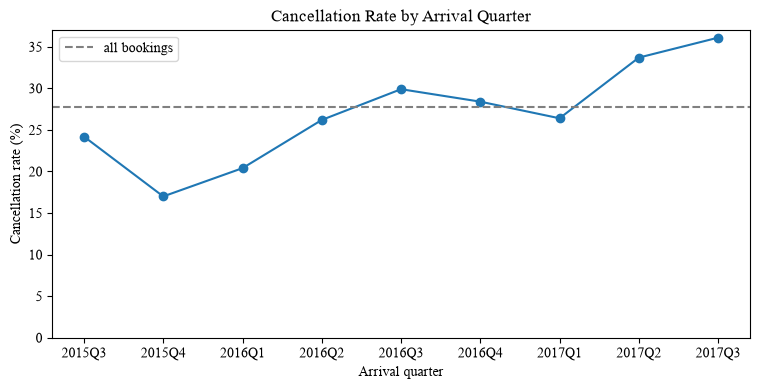

In [39]:
plt.figure(figsize=(9, 4))
plt.plot(quarterly.index, quarterly['cancel_rate'], marker='o')
plt.axhline(hotel_df[TARGET].mean() * 100, color='grey', linestyle='--', label='all bookings')
plt.ylim(0, None)
plt.xlabel('Arrival quarter')
plt.ylabel('Cancellation rate (%)')
plt.title('Cancellation Rate by Arrival Quarter')
plt.legend()
plt.savefig(FIGURE_DIR / 'cancellation_rate_by_quarter.png', dpi=200, bbox_inches='tight')
plt.show()

In [40]:
# train on arrivals before the latest year, test on the latest year
latest_year = hotel_df['arrival_date_year'].max()
is_latest = hotel_df['arrival_date_year'] == latest_year
X_past, y_past = X_all[~is_latest], y[~is_latest]
X_future, y_future = X_all[is_latest], y[is_latest]

time_rows = {}
for name, search in candidate_searches.items():
    model = clone(search.best_estimator_).fit(X_past, y_past)
    proba = model.predict_proba(X_future)[:, 1]
    time_rows[f'{name}: random split test'] = test_metrics(y_test, test_predictions[name])
    time_rows[f'{name}: train before {latest_year}, test {latest_year}'] = test_metrics(y_future, proba >= chosen_threshold[name])
time_check = pd.DataFrame(time_rows).T.round(3)
time_check

,f1,recall,precision,balanced_accuracy,accuracy
M1 logistic regression: random split test,0.598,0.678,0.535,0.726,0.747
"M1 logistic regression: train before 2017, test 2017",0.584,0.635,0.540,0.690,0.710
M2 random forest: random split test,0.672,0.751,0.609,0.783,0.797
"M2 random forest: train before 2017, test 2017",0.600,0.598,0.601,0.705,0.744


**Interpretation:**

* The cancellation rate rises over time, from 17.0% in 2015 Q4 to 36.1% in 2017 Q3.
* Trained on arrivals before 2017 and tested on 2017, F1 falls from 0.598 to 0.584 for logistic regression and from 0.672 to 0.600 for the random forest.
* Most of the loss is in recall. The random forest catches 59.8% of 2017 cancellations against 75.1% in the random split, because a model trained on a period with fewer cancellations predicts too few in a period with more.
* The random forest is still the better model, but its lead over logistic regression shrinks from 0.074 to 0.016.

The two test sets differ, so this comparison is indicative only. It does suggest that the random split overstates performance on future bookings. In use, the model's performance should be monitored, it should be retrained on recent bookings, and the threshold should be reviewed as cancellation rates change.

## 12. Save Outputs

In [41]:
pd.DataFrame(experiment_log).to_csv(OUTPUT_DIR / 'experiment_log.csv', index=False)
test_results.to_csv(OUTPUT_DIR / 'test_results.csv')
print(f'Saved {len(experiment_log)} experiment log rows and the test results to {OUTPUT_DIR}/')
print(f'Total notebook runtime: {(time.time() - NOTEBOOK_START) / 60:.1f} minutes')

Saved 36 experiment log rows and the test results to outputs/
Total notebook runtime: 6.2 minutes
